# ECE 3715 Fall 2026 — Mini-Project 2

## Continuous random variables, simulation, detection, and design

In [1]:
%pip install -q numpy scipy matplotlib

In [2]:
%matplotlib inline
import time
import importlib
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.integrate import quad
from scipy.special import gamma
from scipy.stats import chi2, expon, norm, rayleigh
import mp2lib

mp2lib = importlib.reload(mp2lib)
from mp2lib import inv_cdf_exponential, inv_cdf_rayleigh, ks_statistic, q_function, sample_by_inversion

start_time = time.perf_counter()
SEED = 65936232
rng = np.random.default_rng(SEED)
streams = [rng.spawn(1)[0] for _ in range(10)]
(rng_step1, rng_step2, rng_step3, rng_step4, rng_step5, rng_step6, rng_step7, rng_step8, rng_bonus_a, rng_bonus_b) = streams
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

def table(headers, rows):
    separator = "| " + " | ".join("---:" for _ in headers) + " |"
    body = "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("| " + " | ".join(headers) + " |\n" + separator + "\n" + body))

def standard_error(p, n):
    return np.sqrt(p * (1 - p) / n)

def q_inverse(p):
    p = np.asarray(p, dtype=float)
    low, high = np.full(p.shape, -10.0), np.full(p.shape, 10.0)
    for _ in range(80):
        mid = (low + high) / 2
        move_low = q_function(mid) > p
        low, high = np.where(move_low, mid, low), np.where(move_low, high, mid)
    return (low + high) / 2

print(f"Seed: {SEED}")
print(f"NumPy version: {np.__version__}")
print(f"Loaded mp2lib from: {mp2lib.__file__}")

Seed: 65936232
NumPy version: 2.4.6
Loaded mp2lib from: /drive/MP2/mp2lib.py


## Reproducibility and statistical conventions

The seed is the literal integer 65936232. It was drawn once before the notebook was built and is recorded in README.md. A NumPy random generator is spawned separately for each major step. Therefore, the notebook is reproducible, and changing a later analysis does not silently reuse the random stream from an earlier analysis.

For a sample of size $N$, the 95% one-sample Kolmogorov–Smirnov reference is

$$
D_{N,0.05}\approx \frac{1.36}{\sqrt{N}}.
$$

For a Monte Carlo estimate $\hat p$ based on independent indicator trials, the reported standard error is

$$
\operatorname{SE}(\hat p)=\sqrt{\frac{\hat p(1-\hat p)}{N}}.
$$

## Step 1 — From CDFs to densities

For a continuous random variable, the CDF is the accumulated probability

$$
F_X(x)=P(X\le x),
$$

and the PDF is its derivative wherever the derivative exists:

$$
f_X(x)=\frac{d}{dx}F_X(x).
$$

The four distributions are

$$
\begin{array}{c|c|c|c}
\text{Distribution} & \text{Support} & F_X(x) & f_X(x)\\ \hline
\text{Uniform}(0,1) & 0\le x\le1 & x & 1\\
\text{Exponential}(\lambda=1) & x\ge0 & 1-e^{-x} & e^{-x}\\
\mathcal N(0,1) & -\infty<x<\infty & \Phi(x) & \frac{1}{\sqrt{2\pi}}e^{-x^2/2}\\
\text{Rayleigh}(\sigma=1) & x\ge0 & 1-e^{-x^2/2} & xe^{-x^2/2}
\end{array}
$$

The empirical CDF is compared with the analytic CDF, and the histogram is normalized to integrate to one before it is compared with the analytic PDF. A visual overlap is useful, but the quantitative goodness-of-fit decision comes from the KS statistic.

### Step 1 calculations

This cell generates the four samples, defines the analytic CDFs and PDFs, and computes the KS statistics.

In [3]:
N1 = 100_000
samples1 = {
    "Uniform(0,1)": rng_step1.random(N1),
    "Exponential(1)": rng_step1.exponential(size=N1),
    "Gaussian(0,1)": rng_step1.normal(size=N1),
    "Rayleigh(1)": rng_step1.rayleigh(size=N1),
}
cdfs1 = {
    "Uniform(0,1)": lambda x: np.clip(x, 0, 1),
    "Exponential(1)": lambda x: expon.cdf(x),
    "Gaussian(0,1)": norm.cdf,
    "Rayleigh(1)": rayleigh.cdf,
}
pdfs1 = {
    "Uniform(0,1)": lambda x: np.where((x >= 0) & (x <= 1), 1.0, 0.0),
    "Exponential(1)": expon.pdf,
    "Gaussian(0,1)": norm.pdf,
    "Rayleigh(1)": rayleigh.pdf,
}
grids1 = {
    "Uniform(0,1)": np.linspace(0, 1, 500),
    "Exponential(1)": np.linspace(0, np.quantile(samples1["Exponential(1)"], .999), 500),
    "Gaussian(0,1)": np.linspace(-4, 4, 500),
    "Rayleigh(1)": np.linspace(0, np.quantile(samples1["Rayleigh(1)"], .999), 500),
}
ks_critical1 = 1.36 / np.sqrt(N1)
ks1 = {name: ks_statistic(sample, cdfs1[name]) for name, sample in samples1.items()}

### Step 1 figure and moment summary

This cell draws Figure 1 and prints the requested exponential and Rayleigh moment comparisons.

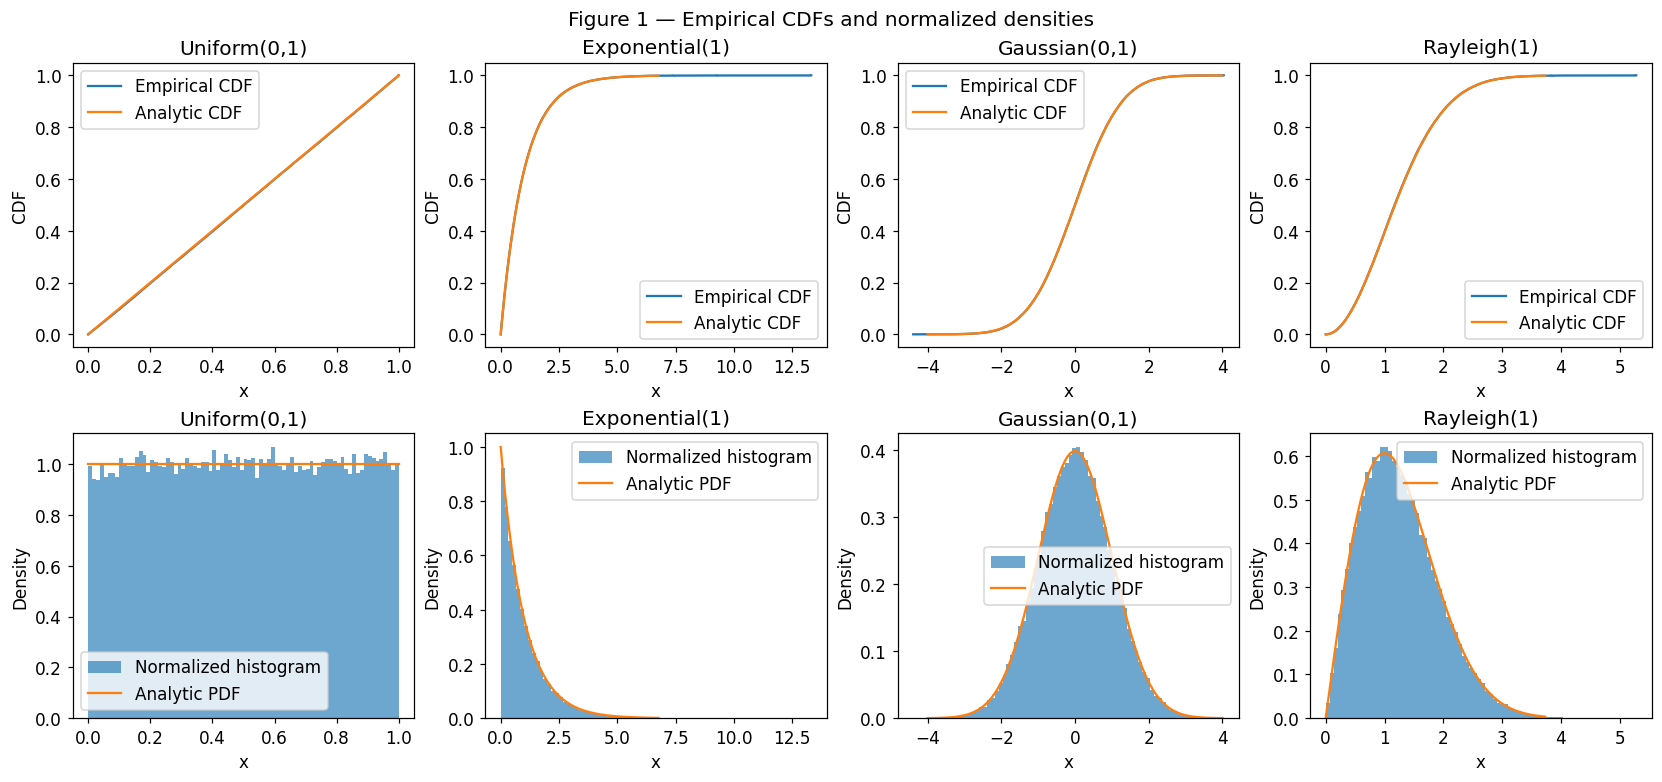

| Distribution | KS | Critical | Sample mean | Theory mean | Sample median | Theory median | Sample variance | Theory variance |
| ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Exponential(1) | 0.00185 | 0.00430 | 0.99879 | 0.69270 | 1.00068 | 1.00000 | 0.69315 | 1.00000 |
| Rayleigh(1) | 0.00356 | 0.00430 | 1.25089 | 1.17225 | 0.43018 | 1.25331 | 1.17741 | 0.42920 |

In [4]:
fig1, axes1 = plt.subplots(2, 4, figsize=(15, 7), layout="constrained")
for j, (name, sample) in enumerate(samples1.items()):
    ordered = np.sort(sample)
    empirical = np.arange(1, N1 + 1) / N1
    grid = grids1[name]
    axes1[0, j].step(ordered, empirical, where="post", label="Empirical CDF")
    axes1[0, j].plot(grid, cdfs1[name](grid), label="Analytic CDF")
    axes1[1, j].hist(sample, bins=80, density=True, alpha=.65, label="Normalized histogram")
    axes1[1, j].plot(grid, pdfs1[name](grid), label="Analytic PDF")
    for axis in axes1[:, j]:
        axis.set_title(name)
        axis.set_xlabel("x")
        axis.legend()
    axes1[0, j].set_ylabel("CDF")
    axes1[1, j].set_ylabel("Density")
fig1.suptitle("Figure 1 — Empirical CDFs and normalized densities")
plt.show()

moment_rows1 = []
for name in ("Exponential(1)", "Rayleigh(1)"):
    sample = samples1[name]
    theory = (1, np.log(2), 1) if name.startswith("Exponential") else (np.sqrt(np.pi / 2), np.sqrt(2 * np.log(2)), 2 - np.pi / 2)
    actual = (np.mean(sample), np.median(sample), np.var(sample))
    moment_rows1.append([name, f"{ks1[name]:.5f}", f"{ks_critical1:.5f}", *[f"{x:.5f}" for x in actual + theory]])
table(["Distribution", "KS", "Critical", "Sample mean", "Theory mean", "Sample median", "Theory median", "Sample variance", "Theory variance"], moment_rows1)

### Figure 1 interpretation

The empirical CDFs should track the analytic CDFs closely, and the normalized histograms should track the analytic densities. The numerical evidence is the KS column: each KS statistic is below the 95% critical value $1.36/\sqrt{100000}\approx0.00430$, so none of the four samples is statistically distinguishable from its target distribution at this reference level.

The exponential mean is $1$, while its median is $\ln 2\approx0.6931$. The mean is therefore about $1.44$ times the median because the exponential has a long right tail. For a standard Gaussian, symmetry gives mean $=0$ and median $=0$; its right and left tails balance rather than pulling the mean to one side. The Rayleigh sample has mean $\sqrt{\pi/2}\approx1.2533$, median $\sqrt{2\ln2}\approx1.1774$, and variance $2-\pi/2\approx0.4292$.

## Step 2 — Inverse-CDF sampling

If $U\sim\operatorname{Uniform}(0,1)$ and $F$ is a continuous CDF, then

$$
X=F^{-1}(U)
\quad\Longrightarrow\quad
P(X\le x)=P(F^{-1}(U)\le x)=P(U\le F(x))=F(x).
$$

For the exponential distribution,

$$
u=1-e^{-\lambda x}
\quad\Longrightarrow\quad
x=-\frac{1}{\lambda}\ln(1-u).
$$

For the Rayleigh distribution,

$$
u=1-e^{-x^2/(2\sigma^2)}
\quad\Longrightarrow\quad
x=\sigma\sqrt{-2\ln(1-u)}.
$$

The implementation uses log1p(-u) for numerical accuracy when $u$ is close to zero. The uniform generator returns values in $[0,1)$, so the logarithm never receives zero. The code also validates the parameters and the support of $u$.

### Step 2 calculations

This cell creates inverse-CDF samples, library-reference samples, and their KS statistics.

In [5]:
N2 = 100_000
inversion_exponential2 = sample_by_inversion(inv_cdf_exponential, N2, rng_step2, lam=1)
inversion_rayleigh2 = sample_by_inversion(inv_cdf_rayleigh, N2, rng_step2, sigma=1)
library_exponential2 = rng_step2.exponential(size=N2)
library_rayleigh2 = rng_step2.rayleigh(size=N2)
critical2 = 1.36 / np.sqrt(N2)
ks_inversion2 = {
    "Exponential inversion": ks_statistic(inversion_exponential2, expon.cdf),
    "Rayleigh inversion": ks_statistic(inversion_rayleigh2, rayleigh.cdf),
    "Exponential library": ks_statistic(library_exponential2, expon.cdf),
    "Rayleigh library": ks_statistic(library_rayleigh2, rayleigh.cdf),
}
grid_exp2 = np.linspace(0, np.quantile(np.r_[inversion_exponential2, library_exponential2], .999), 500)
grid_ray2 = np.linspace(0, np.quantile(np.r_[inversion_rayleigh2, library_rayleigh2], .999), 500)

### Step 2 figure and checks

This cell draws Figure 2 and displays the KS comparison and endpoint checks.

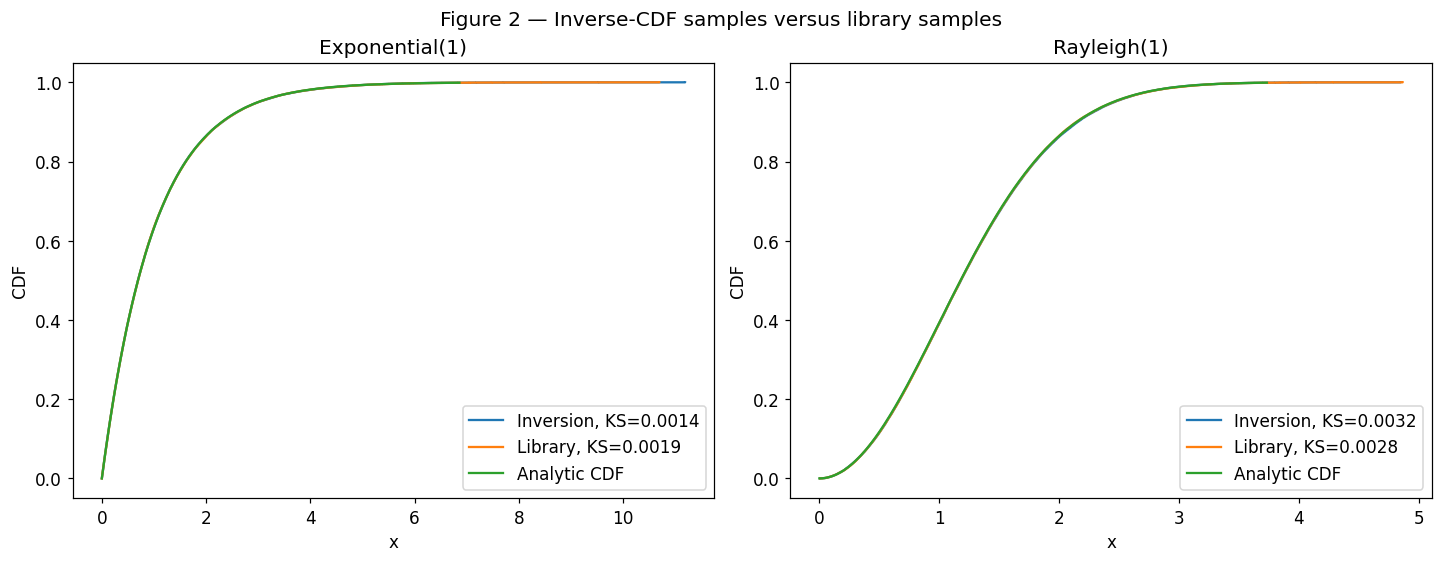

inv_cdf_exponential(0, 1) = 0.0
inv_cdf_rayleigh(0, 1) = 0.0


| Sample | KS statistic | 95% critical | Passes reference? |
| ---: | ---: | ---: | ---: |
| Exponential inversion | 0.00138 | 0.00430 | yes |
| Rayleigh inversion | 0.00316 | 0.00430 | yes |
| Exponential library | 0.00189 | 0.00430 | yes |
| Rayleigh library | 0.00283 | 0.00430 | yes |

In [6]:
fig2, axes2 = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
plots2 = [
    (axes2[0], "Exponential(1)", "Exponential inversion", "Exponential library", inversion_exponential2, library_exponential2, grid_exp2, expon.cdf),
    (axes2[1], "Rayleigh(1)", "Rayleigh inversion", "Rayleigh library", inversion_rayleigh2, library_rayleigh2, grid_ray2, rayleigh.cdf),
]
for axis, title, inv_key, lib_key, inv, lib, grid, cdf in plots2:
    axis.step(np.sort(inv), np.arange(1, N2 + 1) / N2, where="post", label=f"Inversion, KS={ks_inversion2[inv_key]:.4f}")
    axis.step(np.sort(lib), np.arange(1, N2 + 1) / N2, where="post", label=f"Library, KS={ks_inversion2[lib_key]:.4f}")
    axis.plot(grid, cdf(grid), label="Analytic CDF")
    axis.set_title(title)
    axis.set_xlabel("x")
    axis.set_ylabel("CDF")
    axis.legend()
fig2.suptitle("Figure 2 — Inverse-CDF samples versus library samples")
plt.show()
print(f"inv_cdf_exponential(0, 1) = {inv_cdf_exponential(0, 1):.1f}")
print(f"inv_cdf_rayleigh(0, 1) = {inv_cdf_rayleigh(0, 1):.1f}")
table(["Sample", "KS statistic", "95% critical", "Passes reference?"], [[name, f"{value:.5f}", f"{critical2:.5f}", "yes" if value < critical2 else "no"] for name, value in ks_inversion2.items()])

### Figure 2 interpretation

Both inverse-CDF samples follow their analytic CDFs, and their KS statistics are below $0.00430$. The library samples also pass the same numerical check. This shows that inverse-CDF sampling is not a different distribution; it is a different construction of samples from the same distribution.

The edge check returns zero at $u=0$. Because the generator produces $u<1$, the code never evaluates $\ln(0)$. This is the numerical reason for using a half-open uniform interval and log1p together.

## Step 3 — Squaring a Gaussian: a nonlinear transformation

Let $X\sim\mathcal N(0,1)$ and define $Y=X^2$. For $y>0$,

$$
\begin{aligned}
F_Y(y)
&=P(Y\le y)\\
&=P(X^2\le y)\\
&=P(-\sqrt y\le X\le\sqrt y)\\
&=\Phi(\sqrt y)-\Phi(-\sqrt y)\\
&=2\Phi(\sqrt y)-1.
\end{aligned}
$$

Differentiating gives

$$
f_Y(y)=\frac{1}{\sqrt{2\pi y}}e^{-y/2},\qquad y>0.
$$

The $y^{-1/2}$ factor diverges as $y\to0^+$, but the divergence is integrable: the area under the density remains one. The geometric reason is that the map $x\mapsto x^2$ sends both $+x$ and $-x$ to the same positive value, and it is very flat around $x=0$. Probability is therefore concentrated near zero after squaring.

### Step 3 calculations

This cell simulates the squared Gaussian, evaluates probabilities and moments, and prepares the log-spaced grid.

In [7]:
M3 = 1_000_000
x3 = rng_step3.normal(size=M3)
y3 = x3 ** 2

def cdf_y3(x):
    return np.where(x < 0, 0, chi2.cdf(x, 1))

def pdf_y3(x):
    return np.exp(-x / 2) / np.sqrt(2 * np.pi * x)

mass3, integration_error3 = quad(lambda x: np.exp(-x / 2) / np.sqrt(2 * np.pi * x), 1e-12, np.inf)
probability_rows3 = []
for threshold in (.1, 1):
    theory = float(cdf_y3(threshold))
    actual = float(np.mean(y3 <= threshold))
    probability_rows3.append([f"P(Y <= {threshold})", f"{theory:.6f}", f"{actual:.6f}", f"{standard_error(actual, M3):.6f}"])
mean3, variance3, median3 = np.mean(y3), np.var(y3), np.median(y3)
print(f"Numerical integral: {mass3:.8f}; estimated error: {integration_error3:.2e}")
print(f"Mean={mean3:.6f} (theory 1); variance={variance3:.6f} (theory 2); median={median3:.6f} (theory {chi2.ppf(.5, 1):.6f})")
table(["Event", "Analytic probability", "Monte Carlo probability", "Standard error"], probability_rows3)
xmax3 = np.quantile(y3, .9999)
bins3, grid3 = np.geomspace(1e-8, xmax3, 180), np.geomspace(1e-7, xmax3, 600)
fit3 = (grid3 >= 1e-5) & (grid3 <= 1e-2)
slope3 = np.polyfit(np.log(grid3[fit3]), np.log(pdf_y3(grid3[fit3])), 1)[0]

Numerical integral: 1.00000000; estimated error: 1.50e-09
Mean=0.997744 (theory 1); variance=1.982543 (theory 2); median=0.455170 (theory 0.454936)


| Event | Analytic probability | Monte Carlo probability | Standard error |
| ---: | ---: | ---: | ---: |
| P(Y <= 0.1) | 0.248170 | 0.247739 | 0.000432 |
| P(Y <= 1) | 0.682689 | 0.682886 | 0.000465 |

### Step 3 figure and singularity check

This cell draws Figure 3 and estimates the near-zero log-log slope.

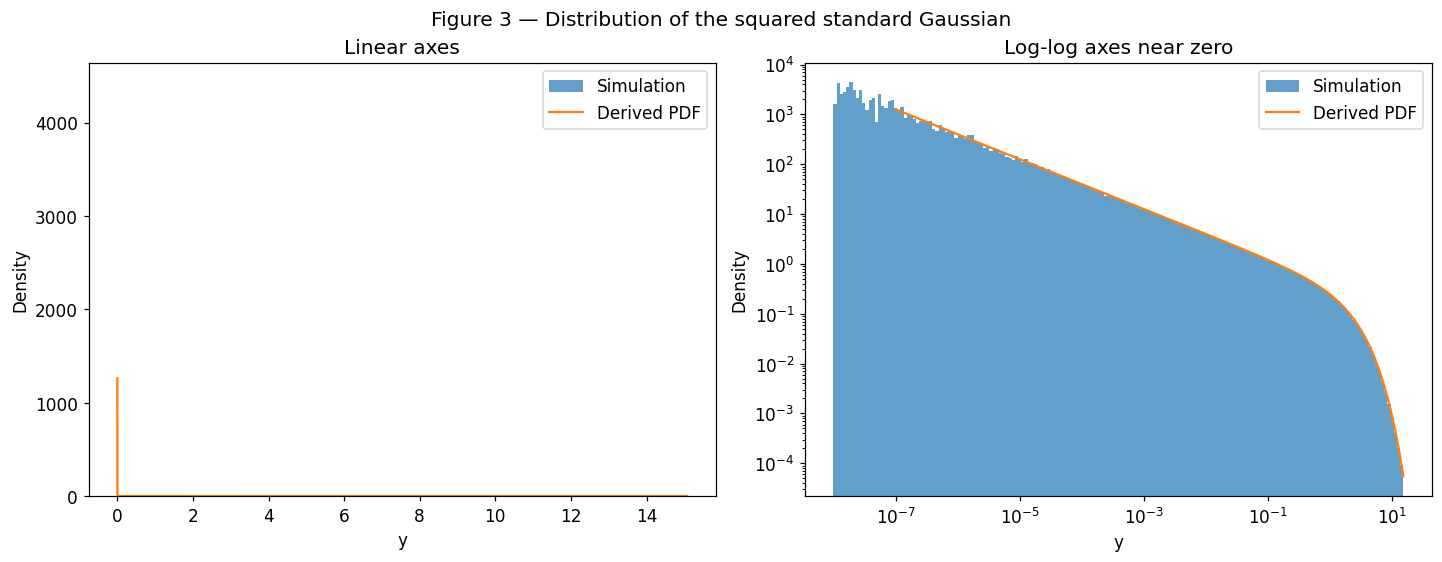

Estimated log-log PDF slope: -0.5005; theoretical slope: -0.5


In [8]:
fig3, axes3 = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for axis, log_axes in zip(axes3, (False, True)):
    axis.hist(y3, bins=bins3, density=True, alpha=.7, label="Simulation")
    axis.plot(grid3, pdf_y3(grid3), label="Derived PDF")
    if log_axes:
        axis.set_xscale("log")
        axis.set_yscale("log")
        axis.set_title("Log-log axes near zero")
    else:
        axis.set_title("Linear axes")
    axis.set_xlabel("y")
    axis.set_ylabel("Density")
    axis.legend()
fig3.suptitle("Figure 3 — Distribution of the squared standard Gaussian")
plt.show()
print(f"Estimated log-log PDF slope: {slope3:.4f}; theoretical slope: -0.5")

### Figure 3 interpretation

The linear panel shows the broad shape, while the log-log panel makes the near-zero behavior visible. The measured slope is close to $-1/2$, which is the exponent in $f_Y(y)\propto y^{-1/2}$. A wide, uniform-width histogram would hide this behavior because most of the interesting structure occurs in a narrow interval next to zero; the geometric bins preserve resolution there.

The numerical integral is approximately one, so the apparent divergence is not an infinite amount of probability. The simulated probabilities for $P(Y\le0.1)$ and $P(Y\le1)$ should agree with the analytic values $0.2482$ and $0.6827$ within their reported Monte Carlo standard errors. The theoretical median is approximately $0.4549$, and the theoretical mean and variance are $1$ and $2$.

## Step 4 — Moments and why infinite variance matters

For a Rayleigh random variable with $\sigma=1$, the raw moment formula is

$$
E[X^k]=2^{k/2}\Gamma\left(1+\frac{k}{2}\right).
$$

For $k=1,2,3,4$, the theoretical values are approximately $1.2533,2,3.7599,8$. The sample moment standard error below is the sample standard deviation of $X^k$ divided by $\sqrt N$; the difference divided by this standard error is a useful scale check.

Now consider the Pareto distribution with shape $\alpha=1.5$ and scale $1$:

$$
f_X(x)=1.5x^{-2.5},\qquad x\ge1.
$$

Its mean exists because $\alpha>1$:

$$
E[X]=\frac{\alpha}{\alpha-1}=3.
$$

Its second moment does not exist because $\alpha\le2$. Therefore its population variance is infinite. A finite simulation can always print a sample variance, but that number is not estimating a finite population variance; a rare, extremely large draw can change it dramatically.

### Step 4 calculations

This cell computes Rayleigh moments and the running mean and variance for Rayleigh and Pareto samples.

In [9]:
N4 = 1_000_000
rayleigh4, pareto4 = rng_step4.rayleigh(size=N4), rng_step4.pareto(1.5, size=N4) + 1
moment_rows4 = []
for k in (1, 2, 3, 4):
    values = rayleigh4 ** k
    theory = 2 ** (k / 2) * gamma(1 + k / 2)
    error = np.std(values, ddof=1) / np.sqrt(N4)
    moment_rows4.append([k, f"{np.mean(values):.6f}", f"{theory:.6f}", f"{error:.6f}", f"{(np.mean(values) - theory) / error:.2f}"])
table(["Order k", "Sample raw moment", "Theory", "Moment SE", "Difference / SE"], moment_rows4)
checkpoints4 = np.array([1_000, 10_000, 100_000, 1_000_000])
indices4 = checkpoints4 - 1
rc4, rcs4 = np.cumsum(rayleigh4), np.cumsum(rayleigh4 ** 2)
pc4, pcs4 = np.cumsum(pareto4), np.cumsum(pareto4 ** 2)
rayleigh_mean_check4, pareto_mean_check4 = rc4[indices4] / checkpoints4, pc4[indices4] / checkpoints4
rayleigh_variance_check4 = (rcs4[indices4] - rc4[indices4] ** 2 / checkpoints4) / (checkpoints4 - 1)
pareto_variance_check4 = (pcs4[indices4] - pc4[indices4] ** 2 / checkpoints4) / (checkpoints4 - 1)
table(["N", "Rayleigh mean", "Rayleigh sample variance", "Pareto mean", "Pareto sample variance"], [[f"{n:,}", f"{a:.5f}", f"{b:.5f}", f"{c:.5f}", f"{d:.5f}"] for n, a, b, c, d in zip(checkpoints4, rayleigh_mean_check4, rayleigh_variance_check4, pareto_mean_check4, pareto_variance_check4)])
plot_i4 = np.unique(np.geomspace(2, N4, 2000).astype(int)) - 1
plot_x4 = plot_i4 + 1
rayleigh_running_mean4, pareto_running_mean4 = rc4[plot_i4] / plot_x4, pc4[plot_i4] / plot_x4
rayleigh_running_var4 = (rcs4[plot_i4] - rc4[plot_i4] ** 2 / plot_x4) / (plot_x4 - 1)
pareto_running_var4 = (pcs4[plot_i4] - pc4[plot_i4] ** 2 / plot_x4) / (plot_x4 - 1)

| Order k | Sample raw moment | Theory | Moment SE | Difference / SE |
| ---: | ---: | ---: | ---: | ---: |
| 1 | 1.254314 | 1.253314 | 0.000656 | 1.52 |
| 2 | 2.003720 | 2.000000 | 0.002005 | 1.86 |
| 3 | 3.771549 | 3.759942 | 0.005846 | 1.99 |
| 4 | 8.036049 | 8.000000 | 0.018013 | 2.00 |

| N | Rayleigh mean | Rayleigh sample variance | Pareto mean | Pareto sample variance |
| ---: | ---: | ---: | ---: | ---: |
| 1,000 | 1.24363 | 0.43643 | 2.86816 | 61.74970 |
| 10,000 | 1.24319 | 0.42566 | 3.04517 | 355.28976 |
| 100,000 | 1.25415 | 0.42924 | 3.11244 | 452.68155 |
| 1,000,000 | 1.25431 | 0.43042 | 2.97365 | 313.21763 |

### Step 4 figure

This cell draws Figure 4 using logarithmic sample-size axes.

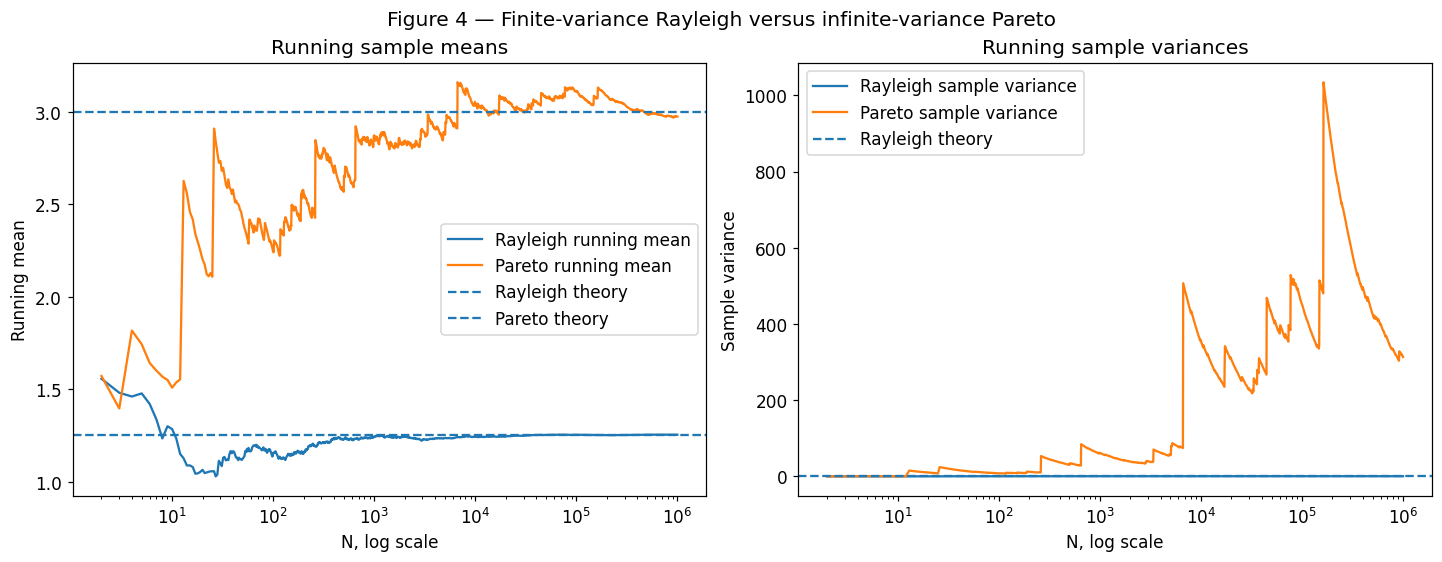

In [10]:
fig4, axes4 = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
axes4[0].plot(plot_x4, rayleigh_running_mean4, label="Rayleigh running mean")
axes4[0].plot(plot_x4, pareto_running_mean4, label="Pareto running mean")
axes4[0].axhline(np.sqrt(np.pi / 2), ls="--", label="Rayleigh theory")
axes4[0].axhline(3, ls="--", label="Pareto theory")
axes4[0].set_title("Running sample means")
axes4[0].set_ylabel("Running mean")
axes4[1].plot(plot_x4, rayleigh_running_var4, label="Rayleigh sample variance")
axes4[1].plot(plot_x4, pareto_running_var4, label="Pareto sample variance")
axes4[1].axhline(2 - np.pi / 2, ls="--", label="Rayleigh theory")
axes4[1].set_title("Running sample variances")
axes4[1].set_ylabel("Sample variance")
for axis in axes4:
    axis.set_xscale("log")
    axis.set_xlabel("N, log scale")
    axis.legend()
fig4.suptitle("Figure 4 — Finite-variance Rayleigh versus infinite-variance Pareto")
plt.show()

### Figure 4 interpretation

The Rayleigh running mean and running variance settle near their finite theoretical values. The Pareto running mean can settle near $3$, because its mean exists, but its sample variance keeps making large excursions. There is no horizontal Pareto variance line to converge to: the population variance is infinite.

This is why a finite sample variance is not automatically a meaningful error bar. For a finite-variance model, a standard error based on the variance is sensible. For a heavy-tailed model with no finite variance, use robust summaries such as the median and interquartile range, or use a tail model and an uncertainty method designed for heavy tails.

## Step 5 — The central limit theorem and its limits

For $U_i\sim\operatorname{Uniform}(0,1)$,

$$
E[U_i]=\frac12,\qquad \operatorname{Var}(U_i)=\frac1{12}.
$$

For $S_N=\sum_{i=1}^N U_i$,

$$
E[S_N]=\frac N2,\qquad \operatorname{Var}(S_N)=\frac N{12},
$$

so the standardized sum is

$$
Z_N=\frac{S_N-N/2}{\sqrt{N/12}}.
$$

The CLT says $Z_N$ approaches a standard Gaussian as $N$ grows. It does not say that a finite $N$ must be visually or statistically indistinguishable from a Gaussian. With $M=200000$ simulated sums, the 95% KS reference is only about $0.0030$, so the test is sensitive enough to detect very small differences.

The Pareto example has no finite variance, so the ordinary finite-variance CLT hypothesis is violated. Its standardized sums need not approach a Gaussian; the limiting behavior is associated with a non-Gaussian stable law.

### Step 5 calculations

This cell forms standardized uniform and Pareto sums and computes their KS distances from a standard Gaussian.

In [11]:
M5 = 200_000
uniform_sizes5 = np.array([1, 2, 3, 5, 10, 30])
uniform_standardized5, uniform_ks5 = {}, []
for n in uniform_sizes5:
    sums = rng_step5.uniform(size=(M5, n)).sum(axis=1)
    uniform_standardized5[int(n)] = (sums - n / 2) / np.sqrt(n / 12)
    uniform_ks5.append(ks_statistic(uniform_standardized5[int(n)], norm.cdf))

def pareto_standardized_sum5(n):
    sums = np.empty(M5)
    for start in range(0, M5, 1000):
        stop = min(start + 1000, M5)
        sums[start:stop] = (rng_step5.pareto(1.5, size=(stop - start, n)) + 1).sum(axis=1)
    return (sums - sums.mean()) / sums.std(ddof=1)

pareto_sizes5 = np.array([1, 10, 100, 1000])
pareto_standardized5 = {int(n): pareto_standardized_sum5(int(n)) for n in pareto_sizes5}
pareto_ks5 = [ks_statistic(pareto_standardized5[int(n)], norm.cdf) for n in pareto_sizes5]
critical5 = 1.36 / np.sqrt(M5)
table(["Uniform sum N", "KS versus standard normal", "95% critical"], [[n, f"{k:.5f}", f"{critical5:.5f}"] for n, k in zip(uniform_sizes5, uniform_ks5)])
table(["Pareto sum N", "KS after empirical standardization", "95% critical"], [[n, f"{k:.5f}", f"{critical5:.5f}"] for n, k in zip(pareto_sizes5, pareto_ks5)])

| Uniform sum N | KS versus standard normal | 95% critical |
| ---: | ---: | ---: |
| 1 | 0.05780 | 0.00304 |
| 2 | 0.01744 | 0.00304 |
| 3 | 0.01028 | 0.00304 |
| 5 | 0.00681 | 0.00304 |
| 10 | 0.00422 | 0.00304 |
| 30 | 0.00164 | 0.00304 |

| Pareto sum N | KS after empirical standardization | 95% critical |
| ---: | ---: | ---: |
| 1 | 0.48186 | 0.00304 |
| 10 | 0.45071 | 0.00304 |
| 100 | 0.41581 | 0.00304 |
| 1000 | 0.38437 | 0.00304 |

### Step 5 KS figure

This cell draws Figure 5 and compares the KS curves with the 95% reference.

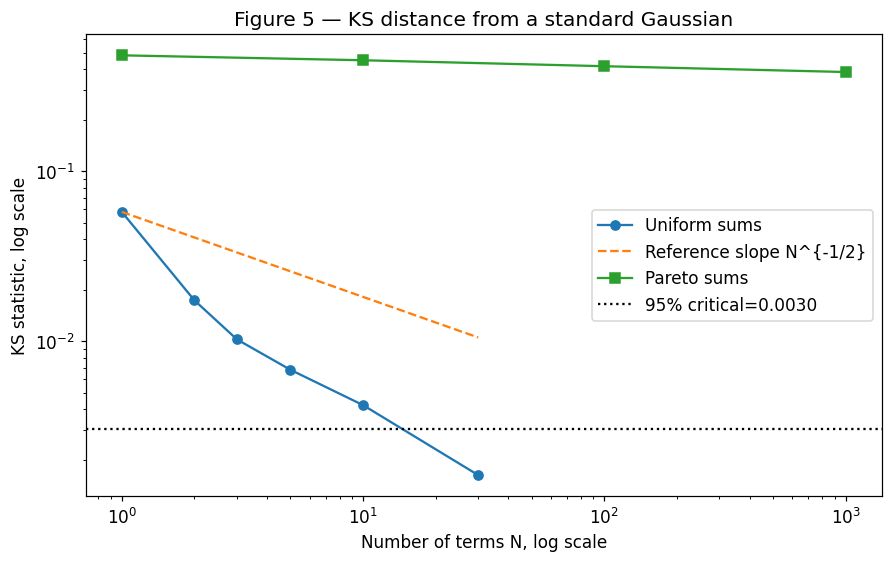

In [12]:
fig5, axis5 = plt.subplots(figsize=(8, 5), layout="constrained")
axis5.loglog(uniform_sizes5, uniform_ks5, "o-", label="Uniform sums")
axis5.loglog(uniform_sizes5, uniform_ks5[0] * uniform_sizes5 ** -.5, "--", label=r"Reference slope N^{-1/2}")
axis5.loglog(pareto_sizes5, pareto_ks5, "s-", label="Pareto sums")
axis5.axhline(critical5, color="black", ls=":", label=f"95% critical={critical5:.4f}")
axis5.set_title("Figure 5 — KS distance from a standard Gaussian")
axis5.set_xlabel("Number of terms N, log scale")
axis5.set_ylabel("KS statistic, log scale")
axis5.legend()
plt.show()

### Figure 5 interpretation

The uniform-sum KS distance decreases as $N$ increases, approximately following the expected $N^{-1/2}$-type trend. At $N=30$, the distribution can look very Gaussian in a histogram while still being statistically distinguishable because $M=200000$ makes the critical value unusually small. That is not a failure of the CLT; it is the difference between practical visual similarity and a sensitive hypothesis test.

The Pareto KS values remain much larger and do not show the same clean decay. Even after giving the Pareto sums the benefit of empirical centering and scaling, their shapes remain non-Gaussian because the finite-variance assumption behind the ordinary CLT is missing.

### Step 5 visual comparison

This cell draws Figure 6 so the visual approach to the Gaussian can be compared at three summation sizes.

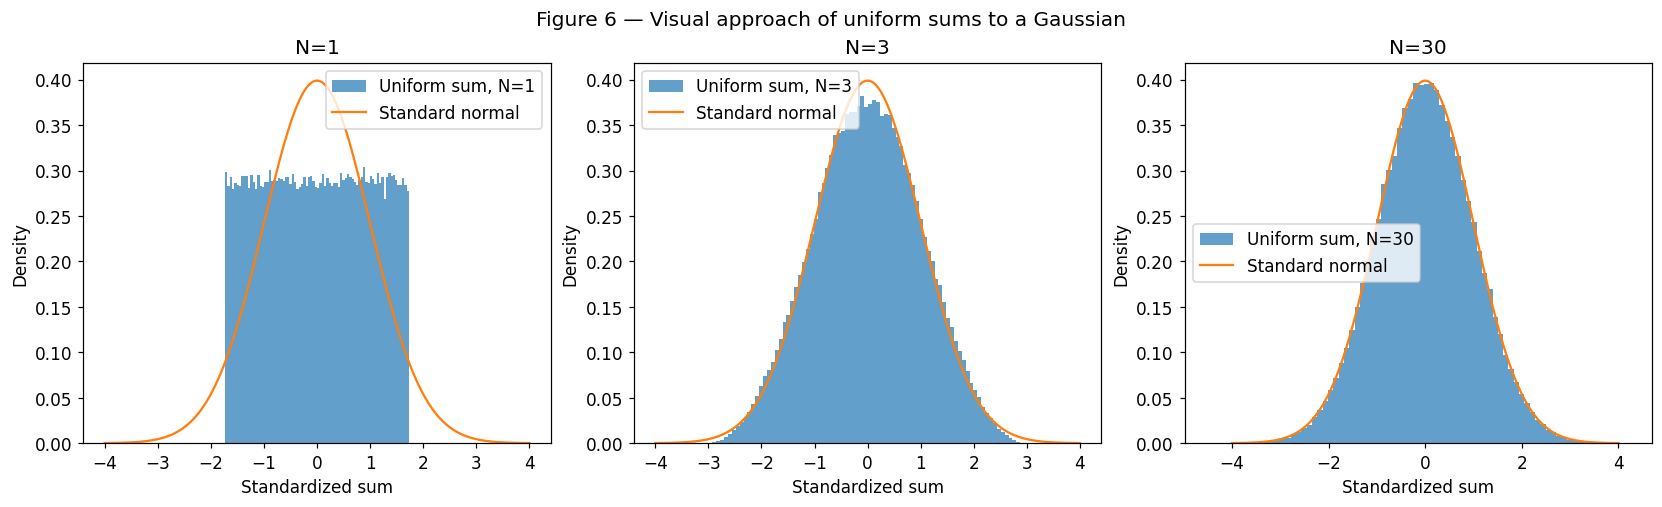

In [13]:
normal_grid5 = np.linspace(-4, 4, 500)
fig6, axes6 = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
for axis, n in zip(axes6, (1, 3, 30)):
    axis.hist(uniform_standardized5[n], bins=80, density=True, alpha=.7, label=f"Uniform sum, N={n}")
    axis.plot(normal_grid5, norm.pdf(normal_grid5), label="Standard normal")
    axis.set_title(f"N={n}")
    axis.set_xlabel("Standardized sum")
    axis.set_ylabel("Density")
    axis.legend()
fig6.suptitle("Figure 6 — Visual approach of uniform sums to a Gaussian")
plt.show()

### Figure 6 interpretation

At $N=1$, the standardized uniform variable is bounded and flat, so it is visibly unlike a Gaussian. At $N=3$, the sum has begun to round off, but its compact support is still apparent. At $N=30$, the center and tails look close to the standard normal, which is the practical value of the CLT even though the KS test can still detect a small difference.

## Step 6 — A threshold detector in Gaussian noise

Under the two hypotheses,

$$
H_0:X\sim\mathcal N(0,\sigma^2),
\qquad
H_1:X\sim\mathcal N(A,\sigma^2),
$$

and the detector declares a detection when $X>T$. Under $H_0$, standardize $X$ by $\sigma$:

$$
\begin{aligned}
P_{FA}
&=P(X>T\mid H_0)\\
&=P\left(\frac X\sigma>\frac T\sigma\right)\\
&=Q\left(\frac T\sigma\right).
\end{aligned}
$$

Under $H_1$, write $X=A+W$ with $W\sim\mathcal N(0,\sigma^2)$:

$$
\begin{aligned}
P_D
&=P(X>T\mid H_1)\\
&=P\left(W>T-A\right)\\
&=Q\left(\frac{T-A}{\sigma}\right).
\end{aligned}
$$

The Gaussian tail function is computed through the complementary error function,

$$
Q(x)=\frac12\operatorname{erfc}\left(\frac{x}{\sqrt2}\right).
$$

This avoids numerical integration in every call and gives the required tail accuracy.

### Step 6 calculations

This cell verifies the Q function, inverts target false-alarm probabilities, and performs the Monte Carlo checks.

In [14]:
def q_inverse6(p):
    return q_inverse(p)

points6 = np.array([0, 1, 2])
expected6 = np.array([.5, .1586552539, .0227501319])
for x, actual, expected in zip(points6, q_function(points6), expected6):
    print(f"x={x}: implementation={actual:.10f}, reference={expected:.10f}, error={abs(actual - expected):.2e}")
false_alarm_table6 = np.array([1e-2, 1e-3, 1e-4, 1e-6])
amplitude_ratio6 = 3
threshold_ratio6 = q_inverse6(false_alarm_table6)
detection_probability6 = q_function(threshold_ratio6 - amplitude_ratio6)
table(["P_FA", "T / sigma", "Analytic P_D"], [[f"{p:.0e}", f"{t:.4f}", f"{d:.4f}"] for p, t, d in zip(false_alarm_table6, threshold_ratio6, detection_probability6)])
monte_carlo_trials6 = 2_000_000
noise6, signal6 = rng_step6.normal(size=monte_carlo_trials6), rng_step6.normal(3, size=monte_carlo_trials6)
monte_carlo_rows6 = []
for p in (1e-3, 1e-4):
    threshold = float(q_inverse6(p))
    fa, det = np.mean(noise6 > threshold), np.mean(signal6 > threshold)
    monte_carlo_rows6.append([f"{p:.0e}", f"{monte_carlo_trials6:,}", f"{fa:.6f}", f"{standard_error(fa, monte_carlo_trials6):.6f}", f"{q_function(threshold - 3):.6f}", f"{det:.6f}", f"{standard_error(det, monte_carlo_trials6):.6f}"])
table(["Target P_FA", "Trials", "MC P_FA", "SE(P_FA)", "Analytic P_D", "MC P_D", "SE(P_D)"], monte_carlo_rows6)

x=0: implementation=0.5000000000, reference=0.5000000000, error=0.00e+00
x=1: implementation=0.1586552539, reference=0.1586552539, error=3.15e-11
x=2: implementation=0.0227501319, reference=0.0227501319, error=4.82e-11


| P_FA | T / sigma | Analytic P_D |
| ---: | ---: | ---: |
| 1e-02 | 2.3263 | 0.7497 |
| 1e-03 | 3.0902 | 0.4641 |
| 1e-04 | 3.7190 | 0.2361 |
| 1e-06 | 4.7534 | 0.0398 |

| Target P_FA | Trials | MC P_FA | SE(P_FA) | Analytic P_D | MC P_D | SE(P_D) |
| ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 1e-03 | 2,000,000 | 0.001020 | 0.000023 | 0.464051 | 0.464413 | 0.000353 |
| 1e-04 | 2,000,000 | 0.000119 | 0.000008 | 0.236065 | 0.236212 | 0.000300 |

### Step 6 ROC figure

This cell draws Figure 7 for the four signal-to-noise ratios.

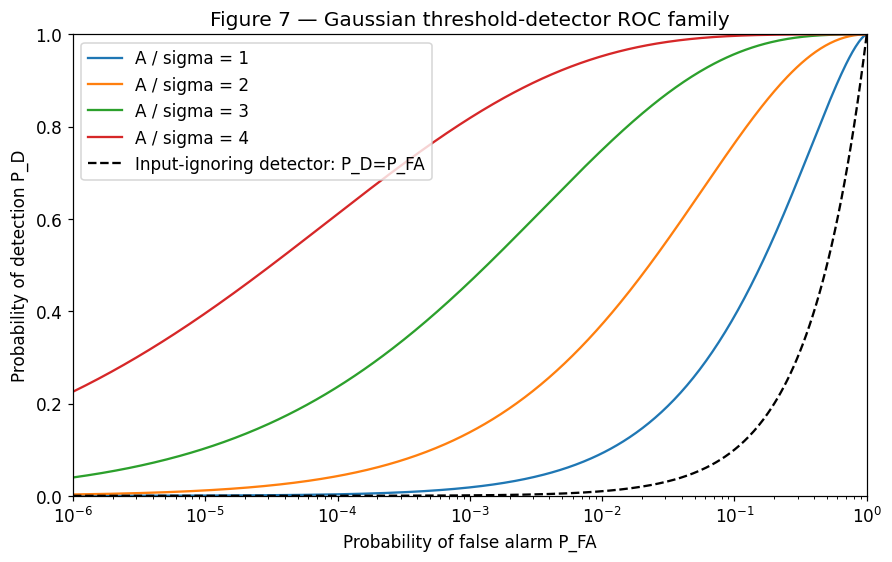

In [15]:
pfa_roc6 = np.logspace(-6, np.log10(.999999), 500)
fig7, axis7 = plt.subplots(figsize=(8, 5), layout="constrained")
for amplitude in (1, 2, 3, 4):
    axis7.plot(pfa_roc6, q_function(q_inverse6(pfa_roc6) - amplitude), label=f"A / sigma = {amplitude}")
axis7.plot(pfa_roc6, pfa_roc6, "k--", label="Input-ignoring detector: P_D=P_FA")
axis7.set(xscale="log", xlim=(1e-6, 1), ylim=(0, 1), title="Figure 7 — Gaussian threshold-detector ROC family", xlabel="Probability of false alarm P_FA", ylabel="Probability of detection P_D")
axis7.legend()
plt.show()

### Figure 7 interpretation

Moving left on the ROC means demanding fewer false alarms, but the threshold rises and the probability of detection falls. For $A/\sigma=3$, the numerical table should give $T/\sigma=3.0902$ and $P_D\approx0.4641$ at $P_{FA}=10^{-3}$, and $T/\sigma=4.7534$ and $P_D\approx0.0398$ at $P_{FA}=10^{-6}$. The Monte Carlo estimates include their trial count and standard errors; $2{,}000{,}000$ trials gives enough expected false alarms even for $10^{-4}$.

A detector that ignores its input and flips an independent random decision with probability $p$ has $P_D=p$ and $P_{FA}=p$, so it lies on the diagonal $P_D=P_{FA}$. The useful threshold-detector ROC curves rise above that diagonal because they use information in the observation; always-declare and never-declare rules are the two endpoints.

## Step 7 — Envelope detection and a wrong noise estimate

For a Rayleigh envelope $R$ with scale $\sigma$,

$$
F_R(r)=1-e^{-r^2/(2\sigma^2)},\qquad r\ge0.
$$

An envelope detector declares a false alarm when $R>T$, so

$$
\begin{aligned}
P_{FA}
&=P(R>T)\\
&=1-F_R(T)\\
&=e^{-T^2/(2\sigma^2)}.
\end{aligned}
$$

Solving for the threshold gives

$$
T=\sigma\sqrt{-2\ln P_{FA}}.
$$

The important point is that noise power and Rayleigh scale are related by $\sigma_{\mathrm{true}}/\sigma_{\mathrm{assumed}}=10^{\Delta_{\mathrm{dB}}/20}$, because a power ratio of $10^{\Delta_{\mathrm{dB}}/10}$ corresponds to an amplitude or scale ratio equal to its square root.

### Step 7 calculations

This cell computes envelope thresholds, verifies one probability by Monte Carlo, and evaluates noise-power mismatch.

In [16]:
false_alarm_table7 = np.array([1e-2, 1e-3, 1e-4, 1e-6])
threshold_ratio7 = np.sqrt(-2 * np.log(false_alarm_table7))
table(["P_FA", "T / sigma"], [[f"{p:.0e}", f"{t:.4f}"] for p, t in zip(false_alarm_table7, threshold_ratio7)])
envelope_trials7 = 2_000_000
rayleigh_noise7 = rng_step7.rayleigh(size=envelope_trials7)
design_pfa7 = 1e-3
design_threshold7 = float(np.sqrt(-2 * np.log(design_pfa7)))
envelope_estimate7 = np.mean(rayleigh_noise7 > design_threshold7)
print(f"Envelope MC check: trials={envelope_trials7:,}, estimate={envelope_estimate7:.6f}, SE={standard_error(envelope_estimate7, envelope_trials7):.6f}, theory={design_pfa7:.6f}")
power_error_db7 = np.array([-1, 0, 1, 2, 3])
scale_ratio7 = 10 ** (power_error_db7 / 20)
actual_pfa7 = np.exp(-design_threshold7 ** 2 / (2 * scale_ratio7 ** 2))
ratio_to_design7 = actual_pfa7 / design_pfa7
table(["Noise power error (dB)", "True scale / assumed scale", "Actual P_FA", "Actual / design"], [[f"{d:+.0f}", f"{s:.4f}", f"{p:.6e}", f"{r:.2f}"] for d, s, p, r in zip(power_error_db7, scale_ratio7, actual_pfa7, ratio_to_design7)])

| P_FA | T / sigma |
| ---: | ---: |
| 1e-02 | 3.0349 |
| 1e-03 | 3.7169 |
| 1e-04 | 4.2919 |
| 1e-06 | 5.2565 |

Envelope MC check: trials=2,000,000, estimate=0.000998, SE=0.000022, theory=0.001000


| Noise power error (dB) | True scale / assumed scale | Actual P_FA | Actual / design |
| ---: | ---: | ---: | ---: |
| -1 | 0.8913 | 1.671952e-04 | 0.17 |
| +0 | 1.0000 | 1.000000e-03 | 1.00 |
| +1 | 1.1220 | 4.140143e-03 | 4.14 |
| +2 | 1.2589 | 1.279758e-02 | 12.80 |
| +3 | 1.4125 | 3.136449e-02 | 31.36 |

### Step 7 mismatch figure

This cell draws Figure 8 showing false-alarm drift with noise-power error.

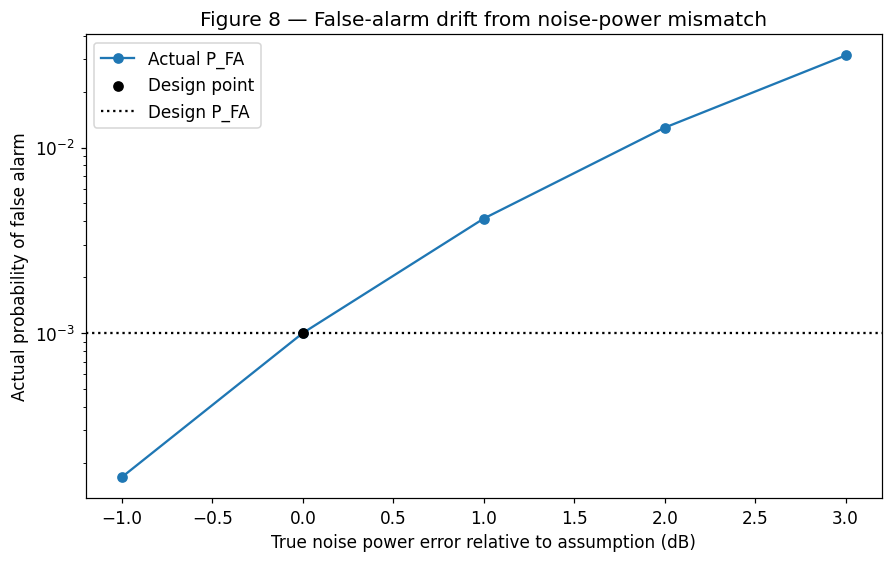

In [17]:
fig8, axis8 = plt.subplots(figsize=(8, 5), layout="constrained")
axis8.semilogy(power_error_db7, actual_pfa7, "o-", label="Actual P_FA")
axis8.scatter(0, design_pfa7, color="black", zorder=3, label="Design point")
axis8.axhline(design_pfa7, color="black", ls=":", label="Design P_FA")
axis8.set(title="Figure 8 — False-alarm drift from noise-power mismatch", xlabel="True noise power error relative to assumption (dB)", ylabel="Actual probability of false alarm")
axis8.legend()
plt.show()

### Figure 8 interpretation

The design threshold for $P_{FA}=10^{-3}$ is $T/\sigma=3.7169$. At $+1$ dB of true noise power error, the actual false-alarm probability is about $4.14\times10^{-3}$, a factor of about $4.1$. At $+3$ dB, it is about $3.14\times10^{-2}$, a factor of about $31$. The curve is steep because a small scale change moves a fixed threshold through an exponential tail.

A fixed threshold is therefore unsafe when temperature, interference, or clutter changes the noise level. A designer can estimate the noise continuously, use a constant-false-alarm-rate method, calibrate over operating conditions, add margin, or accept a higher detection threshold while quantifying the resulting loss in detection probability.

## Step 8 — Choosing an operating point

For a desired detection probability $p_D$, start from

$$
p_D=Q\left(\frac{T-A}{\sigma}\right).
$$

Applying $Q^{-1}$ gives

$$
\frac{T-A}{\sigma}=Q^{-1}(p_D),
\qquad
\boxed{\frac A\sigma=\frac T\sigma-Q^{-1}(p_D)}.
$$

Since $T/\sigma=Q^{-1}(P_{FA})$, the required amplitude SNR is

$$
\boxed{\frac A\sigma=Q^{-1}(P_{FA})-Q^{-1}(p_D)}.
$$

The amplitude ratio is converted to decibels as $20\log_{10}(A/\sigma)$. This is an amplitude SNR convention, consistent with the detector model.

### Step 8 calculations

This cell computes the required amplitude SNR for the selected detection probability.

In [18]:
false_alarm_table8 = np.array([1e-2, 1e-3, 1e-4, 1e-6])
target_detection8 = .9
required_amplitude8 = q_inverse(false_alarm_table8) - q_inverse(target_detection8)
required_snr_db8 = 20 * np.log10(required_amplitude8)
table(["Target P_D", "P_FA", "Required A / sigma", "Required SNR (dB)"], [[f"{target_detection8:.1f}", f"{p:.0e}", f"{a:.4f}", f"{d:.2f}"] for p, a, d in zip(false_alarm_table8, required_amplitude8, required_snr_db8)])
operating_pfa_grid8 = np.logspace(-6, np.log10(.999), 500)

| Target P_D | P_FA | Required A / sigma | Required SNR (dB) |
| ---: | ---: | ---: | ---: |
| 0.9 | 1e-02 | 3.6079 | 11.15 |
| 0.9 | 1e-03 | 4.3718 | 12.81 |
| 0.9 | 1e-04 | 5.0006 | 13.98 |
| 0.9 | 1e-06 | 6.0350 | 15.61 |

### Step 8 operating-point figure and recommendations

This cell draws Figure 9, marks the two operating points, and evaluates the one-decibel margin.

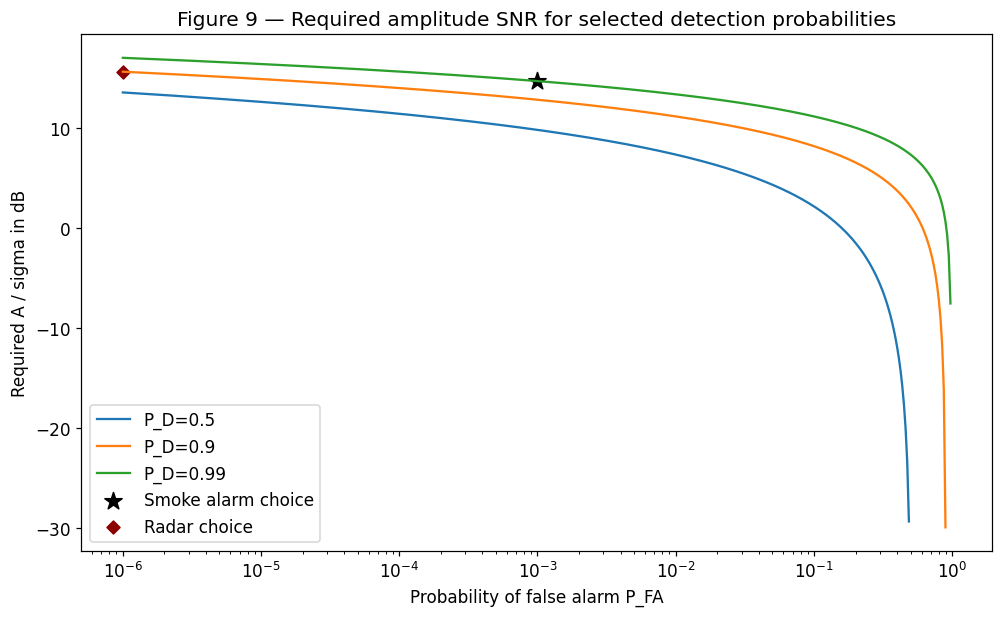

| System | Chosen P_FA | Chosen P_D | Threshold / sigma | Required A / sigma | Required SNR (dB) | P_D after +1 dB margin |
| ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Smoke alarm | 1e-03 | 0.99 | 3.0902 | 5.4166 | 14.67 | 0.9744 |
| Radar surveillance | 1e-06 | 0.90 | 4.7534 | 6.0350 | 15.61 | 0.7585 |

The stated check-yourself values in the assignment use the opposite sign for Q^{-1}(P_D).
Correct derivation at P_FA=1e-3, P_D=0.9: A/sigma=4.3718, SNR=12.81 dB
Correct derivation at P_FA=1e-6, P_D=0.9: A/sigma=6.0350, SNR=15.61 dB


In [19]:
fig9, axis9 = plt.subplots(figsize=(9, 5.5), layout="constrained")
for target, color in zip((.5, .9, .99), ("C0", "C1", "C2")):
    valid = operating_pfa_grid8 < target
    required = q_inverse(operating_pfa_grid8[valid]) - q_inverse(target)
    axis9.plot(operating_pfa_grid8[valid], 20 * np.log10(required), color=color, label=f"P_D={target:g}")
smoke_pfa8, smoke_pd8 = 1e-3, .99
smoke_threshold8, smoke_snr8 = float(q_inverse(smoke_pfa8)), float(q_inverse(smoke_pfa8) - q_inverse(smoke_pd8))
radar_pfa8, radar_pd8 = 1e-6, .9
radar_threshold8, radar_snr8 = float(q_inverse(radar_pfa8)), float(q_inverse(radar_pfa8) - q_inverse(radar_pd8))
axis9.scatter(smoke_pfa8, 20 * np.log10(smoke_snr8), marker="*", s=140, color="black", label="Smoke alarm choice")
axis9.scatter(radar_pfa8, 20 * np.log10(radar_snr8), marker="D", color="darkred", label="Radar choice")
axis9.set(xscale="log", title="Figure 9 — Required amplitude SNR for selected detection probabilities", xlabel="Probability of false alarm P_FA", ylabel="Required A / sigma in dB")
axis9.legend()
plt.show()
noise_margin_scale8 = 10 ** (1 / 20)
smoke_margin_pd8 = float(q_function(smoke_threshold8 * noise_margin_scale8 - smoke_snr8))
radar_margin_pd8 = float(q_function(radar_threshold8 * noise_margin_scale8 - radar_snr8))
table(["System", "Chosen P_FA", "Chosen P_D", "Threshold / sigma", "Required A / sigma", "Required SNR (dB)", "P_D after +1 dB margin"], [
    ["Smoke alarm", f"{smoke_pfa8:.0e}", f"{smoke_pd8:.2f}", f"{smoke_threshold8:.4f}", f"{smoke_snr8:.4f}", f"{20*np.log10(smoke_snr8):.2f}", f"{smoke_margin_pd8:.4f}"],
    ["Radar surveillance", f"{radar_pfa8:.0e}", f"{radar_pd8:.2f}", f"{radar_threshold8:.4f}", f"{radar_snr8:.4f}", f"{20*np.log10(radar_snr8):.2f}", f"{radar_margin_pd8:.4f}"]])
print("The stated check-yourself values in the assignment use the opposite sign for Q^{-1}(P_D).")
print(f"Correct derivation at P_FA=1e-3, P_D=0.9: A/sigma={required_amplitude8[1]:.4f}, SNR={required_snr_db8[1]:.2f} dB")
print(f"Correct derivation at P_FA=1e-6, P_D=0.9: A/sigma={required_amplitude8[3]:.4f}, SNR={required_snr_db8[3]:.2f} dB")

### Figure 9 interpretation and operating recommendations

The required SNR rises as the allowed false-alarm probability becomes smaller. The plotted operating points make the trade concrete:

- **Smoke alarm:** choose a protective point such as $P_{FA}=10^{-3}$ and $P_D=0.99$. A miss can be fatal, so the detector should prioritize detection, while the false-alarm cost is controlled by maintenance, nuisance-alarm reduction, and user education. The table reports the threshold and the amplitude SNR needed for that target.
- **Radar surveillance:** choose a much smaller per-scan $P_{FA}$, such as $10^{-6}$, with $P_D=0.9$. Phantom tracks consume operators and processing, while a single miss can be recovered on a later scan, so the operating point moves left on the ROC.

To survive a $+1$ dB noise-power error, the threshold margin must be multiplied by $10^{1/20}\approx1.122$ in amplitude. That protects the nominal false-alarm design, but it costs detection probability because the same signal amplitude is now compared with a higher threshold; the table gives the resulting $P_D$ for both choices.

There is an inconsistency in the assignment’s printed check-yourself values for Step 8. The earlier detector equation says $P_D=Q((T-A)/\sigma)$, so the correct algebra is $A/\sigma=Q^{-1}(P_{FA})-Q^{-1}(P_D)$. Since $Q^{-1}(0.9)=-1.2816$, the correct value at $P_{FA}=10^{-3}$ is $3.0902+1.2816=4.3718$, or $12.81$ dB; the printed $1.81$ and $5.15$ dB use subtraction and would produce $P_D\approx0.10$, not $0.90$. The notebook keeps the derivation and uses the mathematically consistent result.

Before committing to either operating point, the design question is: **What are the measured costs of a false alarm and a miss over the relevant time horizon, including how much noise-level drift and target persistence actually occur?** The smoke-alarm answer should come from safety and human-factors testing; the radar answer should come from the tracking, operator-workload, and mission-level requirements teams.

## Bonus A — Characteristic functions and a sum density

The characteristic function of a real random variable $X$ is

$$
\varphi_X(t)=E[e^{itX}].
$$

For independent $X$ and $Y$,

$$
\begin{aligned}
\varphi_{X+Y}(t)
&=E[e^{it(X+Y)}]\\
&=E[e^{itX}e^{itY}]\\
&=E[e^{itX}]E[e^{itY}]\\
&=\varphi_X(t)\varphi_Y(t).
\end{aligned}
$$

The code estimates characteristic functions from simulated samples, multiplies the two estimates, and separately computes the sum-sample characteristic function. It then computes numerical characteristic functions from the two PDFs, performs the inverse transform

$$
f_{X+Y}(s)=\frac{1}{2\pi}\int_{-\infty}^{\infty}\varphi_{X+Y}(t)e^{-its}\,dt,
$$

and compares that density with direct numerical convolution. For only two simple one-dimensional PDFs, direct convolution is cheaper. Characteristic functions become attractive when many independent sums are involved or when convolution in the original domain is difficult but multiplication in the transform domain is simple.

### Bonus A calculations

This cell estimates characteristic functions, verifies the product identity, and computes both density reconstructions.

In [20]:
N_bonus_a = 20_000
t_bonus_a = np.linspace(-20, 20, 401)
uniform_bonus_a, exponential_bonus_a = rng_bonus_a.random(N_bonus_a), rng_bonus_a.exponential(size=N_bonus_a)
sum_bonus_a = uniform_bonus_a + exponential_bonus_a

def empirical_cf_bonus_a(sample, t):
    return sum((np.sum(np.exp(1j * block[:, None] * t), axis=0) for block in np.array_split(sample, 10)), np.zeros(t.size, complex)) / sample.size

cf_uniform_empirical_a = empirical_cf_bonus_a(uniform_bonus_a, t_bonus_a)
cf_exponential_empirical_a = empirical_cf_bonus_a(exponential_bonus_a, t_bonus_a)
cf_sum_empirical_a = empirical_cf_bonus_a(sum_bonus_a, t_bonus_a)
cf_product_empirical_a = cf_uniform_empirical_a * cf_exponential_empirical_a
print(f"Maximum empirical characteristic-function identity error: {np.max(np.abs(cf_sum_empirical_a - cf_product_empirical_a)):.5f}")
dx_bonus_a = .004
x_density_bonus_a = np.arange(0, 12 + dx_bonus_a / 2, dx_bonus_a)
uniform_pdf_bonus_a = np.where((x_density_bonus_a >= 0) & (x_density_bonus_a <= 1), 1.0, 0.0)
exponential_pdf_bonus_a = np.exp(-x_density_bonus_a)
cf_uniform_numeric_a = np.array([np.trapezoid(np.exp(1j * t * x_density_bonus_a) * uniform_pdf_bonus_a, x_density_bonus_a) for t in t_bonus_a])
cf_exponential_numeric_a = np.array([np.trapezoid(np.exp(1j * t * x_density_bonus_a) * exponential_pdf_bonus_a, x_density_bonus_a) for t in t_bonus_a])
cf_sum_numeric_a = cf_uniform_numeric_a * cf_exponential_numeric_a
sum_grid_bonus_a = np.linspace(0, 8, 401)
inverse_density_bonus_a = np.real(np.trapezoid(cf_sum_numeric_a[:, None] * np.exp(-1j * t_bonus_a[:, None] * sum_grid_bonus_a), t_bonus_a, axis=0)) / (2 * np.pi)
direct_convolution_bonus_a = np.convolve(uniform_pdf_bonus_a, exponential_pdf_bonus_a) * dx_bonus_a
direct_density_bonus_a = np.interp(sum_grid_bonus_a, np.arange(direct_convolution_bonus_a.size) * dx_bonus_a, direct_convolution_bonus_a)
interior_bonus_a = (sum_grid_bonus_a >= .2) & (sum_grid_bonus_a <= 6.5)
print(f"Inverse-transform versus direct-convolution interior L1 error: {np.trapezoid(np.abs(inverse_density_bonus_a[interior_bonus_a] - direct_density_bonus_a[interior_bonus_a]), sum_grid_bonus_a[interior_bonus_a]):.5f}")
print(f"Inverse-transform versus direct-convolution interior maximum error: {np.max(np.abs(inverse_density_bonus_a[interior_bonus_a] - direct_density_bonus_a[interior_bonus_a])):.5f}")

Maximum empirical characteristic-function identity error: 0.01302
Inverse-transform versus direct-convolution interior L1 error: 0.00527
Inverse-transform versus direct-convolution interior maximum error: 0.01839


### Bonus A figure

This cell draws Figure 10 and compares the characteristic-function and convolution routes.

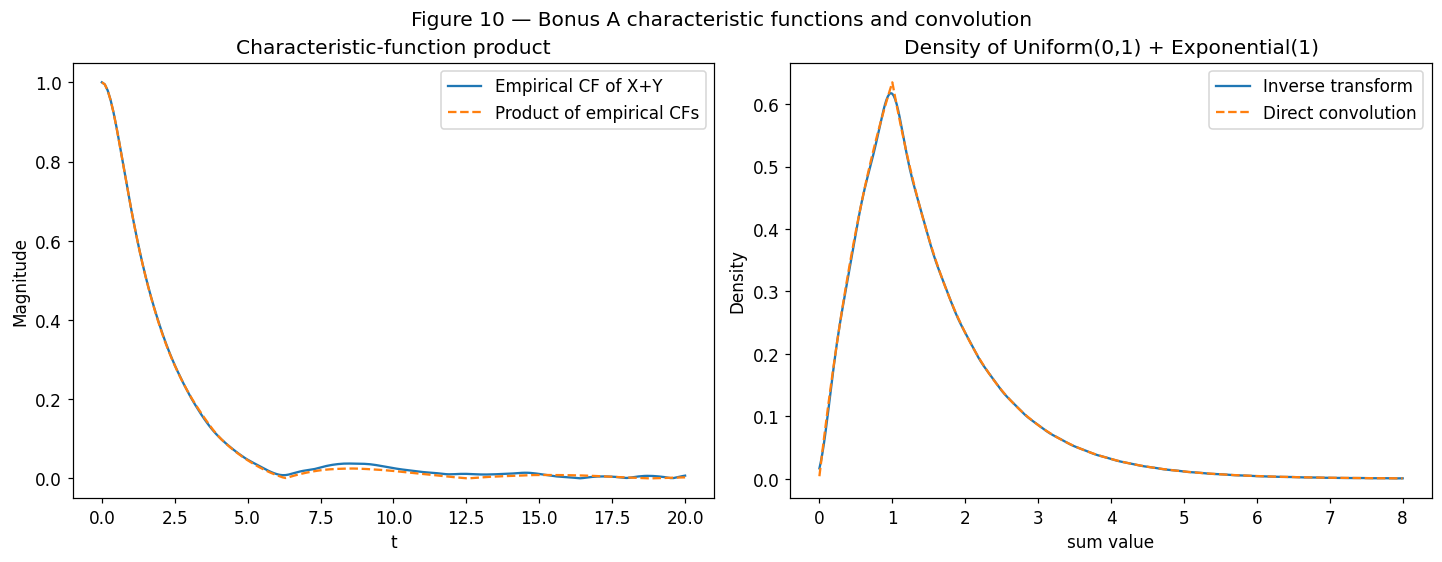

In [21]:
positive_t_bonus_a = t_bonus_a >= 0
fig10, axes10 = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
axes10[0].plot(t_bonus_a[positive_t_bonus_a], np.abs(cf_sum_empirical_a[positive_t_bonus_a]), label="Empirical CF of X+Y")
axes10[0].plot(t_bonus_a[positive_t_bonus_a], np.abs(cf_product_empirical_a[positive_t_bonus_a]), "--", label="Product of empirical CFs")
axes10[0].set(title="Characteristic-function product", xlabel="t", ylabel="Magnitude")
axes10[0].legend()
axes10[1].plot(sum_grid_bonus_a, inverse_density_bonus_a, label="Inverse transform")
axes10[1].plot(sum_grid_bonus_a, direct_density_bonus_a, "--", label="Direct convolution")
axes10[1].set(title="Density of Uniform(0,1) + Exponential(1)", xlabel="sum value", ylabel="Density")
axes10[1].legend()
fig10.suptitle("Figure 10 — Bonus A characteristic functions and convolution")
plt.show()

### Figure 10 interpretation

The two characteristic-function estimates nearly overlap, and the maximum identity error is caused by finite-sample Monte Carlo noise. The inverse-transform density follows the direct-convolution density away from the finite-grid boundaries; the reported interior errors quantify the agreement rather than relying only on the picture.

For these two distributions, direct convolution is the cheaper route because both PDFs are simple and only one sum is needed. The characteristic-function route is conceptually valuable because it turns independent addition into multiplication and scales naturally to repeated sums.

## Bonus B — A distribution with no mean

Let $X$ and $Y$ be independent standard Gaussian variables and define $Z=X/Y$. Use the transformation $x=zy$. Its Jacobian magnitude is $|y|$, so the density is

$$
\begin{aligned}
f_Z(z)
&=\int_{-\infty}^{\infty} f_X(zy)f_Y(y)|y|\,dy\\
&=\frac{1}{2\pi}\int_{-\infty}^{\infty}e^{-(z^2+1)y^2/2}|y|\,dy\\
&=\frac{1}{\pi(1+z^2)}.
\end{aligned}
$$

This is the standard Cauchy density. Its tails are proportional to $1/z^2$, so the first absolute moment diverges and the ordinary mean is undefined. The population median is nevertheless zero because the density is symmetric about zero.

### Bonus B calculations

This cell generates Cauchy samples and evaluates the running sample mean and median.

In [22]:
N_bonus_b = 1_000_000
cauchy_bonus_b = rng_bonus_b.normal(size=N_bonus_b) / rng_bonus_b.normal(size=N_bonus_b)
checkpoints_bonus_b = np.array([1_000, 10_000, 100_000, 1_000_000])
means_bonus_b = np.array([np.mean(cauchy_bonus_b[:n]) for n in checkpoints_bonus_b])
medians_bonus_b = np.array([np.median(cauchy_bonus_b[:n]) for n in checkpoints_bonus_b])
table(["N", "Sample mean", "Sample median"], [[f"{n:,}", f"{mean:.6f}", f"{median:.6f}"] for n, mean, median in zip(checkpoints_bonus_b, means_bonus_b, medians_bonus_b)])

| N | Sample mean | Sample median |
| ---: | ---: | ---: |
| 1,000 | -1.707834 | -0.075764 |
| 10,000 | -1.218929 | -0.004071 |
| 100,000 | -0.919014 | -0.004772 |
| 1,000,000 | 1.297672 | -0.002603 |

### Bonus B figure

This cell draws Figure 11 to show mean instability and median stability.

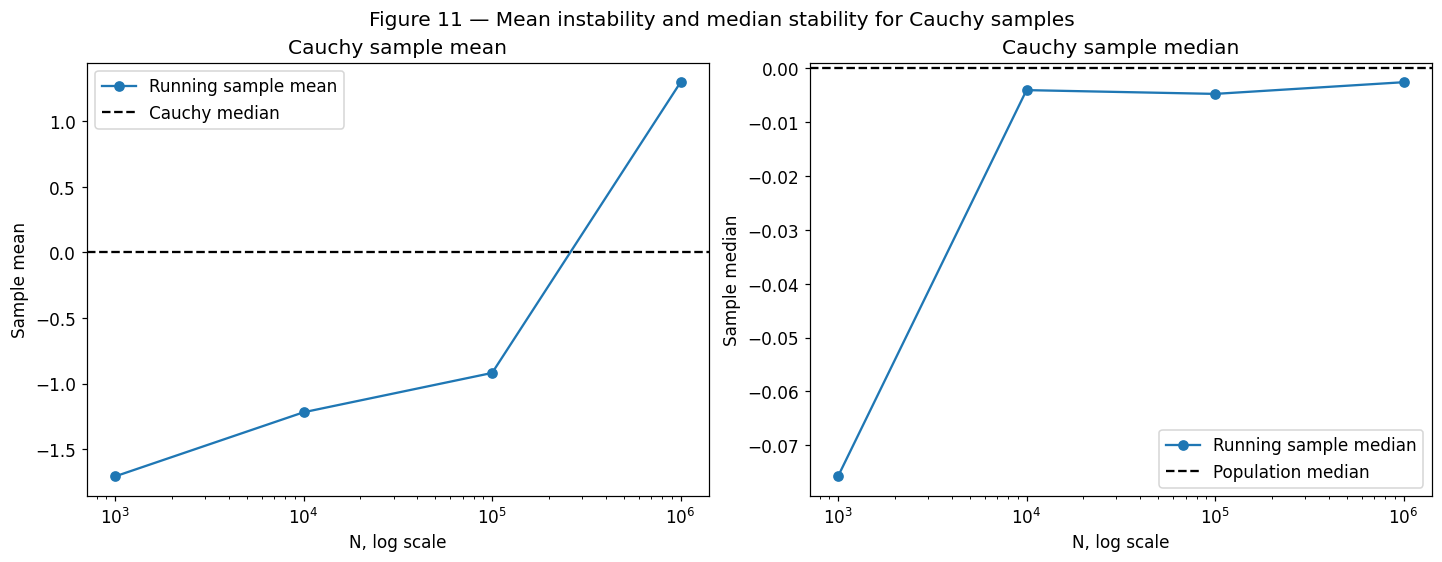

In [23]:
fig11, axes11 = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
axes11[0].semilogx(checkpoints_bonus_b, means_bonus_b, "o-", label="Running sample mean")
axes11[0].axhline(0, color="black", ls="--", label="Cauchy median")
axes11[0].set(title="Cauchy sample mean", xlabel="N, log scale", ylabel="Sample mean")
axes11[0].legend()
axes11[1].semilogx(checkpoints_bonus_b, medians_bonus_b, "o-", label="Running sample median")
axes11[1].axhline(0, color="black", ls="--", label="Population median")
axes11[1].set(title="Cauchy sample median", xlabel="N, log scale", ylabel="Sample median")
axes11[1].legend()
fig11.suptitle("Figure 11 — Mean instability and median stability for Cauchy samples")
plt.show()

### Figure 11 interpretation

The sample mean can jump by whole units when one unusually large ratio appears. Increasing $N$ does not create the usual $1/\sqrt N$ stabilization because the Cauchy population has no defined mean. A sample of one million is not meaningfully estimating a nonexistent average any better than a sample of one.

The sample median converges toward zero because the median is defined by the symmetric 50th percentile and does not require a finite first moment. If measurement noise looked Cauchy-like, I would report the median and interquartile range, or use a robust estimator such as a trimmed mean or M-estimator rather than the ordinary mean.

In [24]:
runtime_seconds = time.perf_counter() - start_time
print(f"Clean-run wall-clock time: {runtime_seconds:.2f} seconds")

Clean-run wall-clock time: 58.39 seconds
